In [1]:
!pip -q install datasets pandas numpy matplotlib pillow opencv-python-headless tqdm

In [2]:
import os
import sys
import json
import base64
import random
import requests
import warnings

from pathlib import Path
from io import BytesIO

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from datasets import load_dataset

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURATION
# ============================================================

SEED = 42

MALARIA_CANDIDATES = 200
PCAM_CANDIDATES = 750

IMAGE_SIZE = (96, 96)

REPO = "Code-maddie/StainNormalization"
BRANCH = "main"

ROOT = Path("/content")
REPO_DIR = ROOT / "StainNormalization"

OUTPUT_DIR = REPO_DIR / "data"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

print("Configuration loaded.")
print("Random seed:", SEED)
print("Malaria candidates:", MALARIA_CANDIDATES)
print("PCam candidates:", PCAM_CANDIDATES)
print("Target image size:", IMAGE_SIZE)

Configuration loaded.
Random seed: 42
Malaria candidates: 200
PCam candidates: 750
Target image size: (96, 96)


In [3]:
from google.colab import userdata

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

if not GITHUB_TOKEN:
    raise RuntimeError(
        "GITHUB_TOKEN not found in Colab Secrets."
    )

HEADERS = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json"
}

API = "https://api.github.com"

SOURCE_FILES = [
    "src/__init__.py",
    "src/normalization/__init__.py",
    "src/normalization/stainNorm_Reinhard.py",
    "src/normalization/stainNorm_Macenko.py",
    "src/normalization/stain_utils.py"
]

print("Downloading source files from GitHub...")

for relative_path in SOURCE_FILES:

    url = (
        f"{API}/repos/{REPO}/contents/"
        f"{relative_path}?ref={BRANCH}"
    )

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=30
    )

    response.raise_for_status()

    file_data = response.json()

    content = base64.b64decode(
        file_data["content"]
    )

    destination = REPO_DIR / relative_path

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    destination.write_bytes(content)

    print("Downloaded:", relative_path)

print("\nAll normalization source files retrieved.")

Downloaded: src/__init__.py
Downloaded: src/normalization/__init__.py
Downloaded: src/normalization/stainNorm_Reinhard.py
Downloaded: src/normalization/stainNorm_Macenko.py
Downloaded: src/normalization/stain_utils.py

All normalization source files retrieved.


In [5]:
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

try:
    import spams
    print("SPAMS imported successfully.")
except ImportError as e:
    raise RuntimeError(
        "SPAMS is not available in this notebook's active "
        "Python environment. Stop here and restore the "
        "working histology38/SPAMS environment. Do not "
        "replace SPAMS with another concentration solver."
    ) from e

from src.normalization import stainNorm_Reinhard as reinhard
from src.normalization import stainNorm_Macenko as macenko
from src.normalization import stain_utils as stain_utils

print("\nNormalization modules imported.")

# Verify the actual functions and class methods.

assert hasattr(reinhard, "get_mean_std")
assert hasattr(reinhard.normalizer, "fit")
assert hasattr(reinhard.normalizer, "transform")

assert hasattr(macenko, "get_stain_matrix")
assert hasattr(macenko.normalizer, "fit")
assert hasattr(macenko.normalizer, "transform")

assert hasattr(stain_utils, "standardize_brightness")
assert hasattr(stain_utils, "RGB_to_OD")
assert hasattr(stain_utils, "get_concentrations")

print("All expected implementation functions exist.")

RuntimeError: SPAMS is not available in this notebook's active Python environment. Stop here and restore the working histology38/SPAMS environment. Do not replace SPAMS with another concentration solver.

In [6]:
import sys
import os
import subprocess

print("Active Python:", sys.executable)
print("Python version:", sys.version)

print("\nConda environment:")
print(os.environ.get("CONDA_DEFAULT_ENV", "No active Conda environment"))

print("\nConda availability:")
result = subprocess.run(
    ["bash", "-lc", "conda env list"],
    capture_output=True,
    text=True
)
print(result.stdout)
print(result.stderr)

Active Python: /usr/bin/python3
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

Conda environment:
No active Conda environment

Conda availability:

bash: line 1: conda: command not found



In [7]:
!pip install -q condacolab

import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:16
🔁 Restarting kernel...


In [1]:
import sys
import subprocess

print("Python:", sys.version)
print("Python executable:", sys.executable)

result = subprocess.run(
    ["conda", "--version"],
    capture_output=True,
    text=True
)

print("Conda:", result.stdout.strip())
print(result.stderr)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python executable: /usr/bin/python3.real
Conda: conda 26.3.2



In [2]:
!conda search -c conda-forge python-spams

Loading channels: - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / done
# Name                       Version           Build  Channel             
python-spams                     2.5 np110py27_blas_openblas_200  conda-forge         
python-spams                     2.5 np110py27_blas_openblas_201  conda-forge         
python-spams                     2.5 np110py27_blas_openblas_202  conda-forge         
python-spams                     2.5 np110py27_blas_openblas_203  conda-forge         
python-spams                     2.5 np110py27_blas_openblas_204  conda-fo

In [3]:
!conda create -y -n histology38 -c conda-forge python=3.8 python-spams=2.6.1

Retrieving notices: - \ done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / done

## Package Plan ##

  environment location: /usr/local/envs/histology38

  added / updated specs:
    - python-spams=2.6.1
    - python=3.8


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    brotli-python-1.1.0        |   py38h17151c0_1         343 KB  conda-forge
    bzip2-1.0.8                |      hda65f42_10         252 KB  conda-forge
    ca-certificates-2026.10.23 |       hbd8a1cb_0         127 KB  conda-forge
    certifi-2024.8.30          |     pyhd8ed1ab_0         160 KB  conda-forge
    cffi-1.17.0                |   py38heb5c249_0         235 KB  conda-forge
    charset-normalizer-3.4.0   |     pyhd8ed1ab_0          46 KB  conda-forge
    h2-4.1.0                   |     pyhd8ed1ab_0          46 KB  conda-forge
    hpack-4.0.0                |     pyh9f0ad1d_0       

In [4]:
import subprocess

result = subprocess.run(
    [
        "conda", "run", "-n", "histology38",
        "python", "-c",
        "import sys, spams; "
        "print('Python:', sys.version); "
        "print('SPAMS:', spams.__file__); "
        "print('LASSO:', hasattr(spams, 'lasso')); "
        "print('trainDL:', hasattr(spams, 'trainDL'))"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print("STDERR:", result.stderr)

assert result.returncode == 0, "SPAMS verification failed."

Python: 3.8.20 | packaged by conda-forge | (default, Sep 30 2024, 17:52:49) 
[GCC 13.3.0]
SPAMS: /usr/local/envs/histology38/lib/python3.8/site-packages/spams.py
LASSO: True
trainDL: True



In [5]:
from pathlib import Path

files = [
    "/content/StainNormalization/src/normalization/stainNorm_Reinhard.py",
    "/content/StainNormalization/src/normalization/stainNorm_Macenko.py",
    "/content/StainNormalization/src/normalization/stain_utils.py"
]

for file_path in files:
    path = Path(file_path)

    print("\n" + "=" * 80)
    print("FILE:", path.name)
    print("=" * 80)

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines, start=1):
        if (
            line.strip().startswith(("import ", "from ", "class ", "def "))
            or "spams." in line
        ):
            print(f"{i:4}: {line}")


FILE: stainNorm_Reinhard.py
   7: import cv2 as cv
   8: import numpy as np
   9: from . import stain_utils as ut
  15: def lab_split(I):
  30: def merge_back(I1, I2, I3):
  45: def get_mean_std(I):
  62: class normalizer(object):
  67:     def __init__(self):
  71:     def fit(self, target):
  77:     def transform(self, I):

FILE: stainNorm_Macenko.py
  13: import numpy as np
  14: from . import stain_utils as ut
  17: def get_stain_matrix(I, beta=0.15, alpha=1):
  46: class normalizer(object):
  51:     def __init__(self):
  55:     def fit(self, target):
  60:     def target_stains(self):
  63:     def transform(self, I):
  73:     def hematoxylin(self, I):

FILE: stain_utils.py
   9: import numpy as np
  10: import cv2 as cv
  11: import spams
  12: import matplotlib.pyplot as plt
  17: def read_image(path):
  28: def show_colors(C):
  44: def show(image, now=True, fig_size=(10, 10)):
  63: def build_stack(tup):
  81: def patch_grid(ims, width=5, sub_sample=None, rand=False, save

In [6]:
from pathlib import Path

files_to_inspect = {
    "stainNorm_Reinhard.py": (15, 90),
    "stainNorm_Macenko.py": (17, 90),
    "stain_utils.py": (115, 205)
}

base = Path("/content/StainNormalization/src/normalization")

for filename, (start, end) in files_to_inspect.items():
    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    lines = (base / filename).read_text().splitlines()

    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:4}: {lines[i-1]}")


stainNorm_Reinhard.py
  15: def lab_split(I):
  16:     """
  17:     Convert from RGB uint8 to LAB and split into channels
  18:     :param I: uint8
  19:     :return:
  20:     """
  21:     I = cv.cvtColor(I, cv.COLOR_RGB2LAB)
  22:     I = I.astype(np.float32)
  23:     I1, I2, I3 = cv.split(I)
  24:     I1 /= 2.55
  25:     I2 -= 128.0
  26:     I3 -= 128.0
  27:     return I1, I2, I3
  28: 
  29: 
  30: def merge_back(I1, I2, I3):
  31:     """
  32:     Take seperate LAB channels and merge back to give RGB uint8
  33:     :param I1:
  34:     :param I2:
  35:     :param I3:
  36:     :return:
  37:     """
  38:     I1 *= 2.55
  39:     I2 += 128.0
  40:     I3 += 128.0
  41:     I = np.clip(cv.merge((I1, I2, I3)), 0, 255).astype(np.uint8)
  42:     return cv.cvtColor(I, cv.COLOR_LAB2RGB)
  43: 
  44: 
  45: def get_mean_std(I):
  46:     """
  47:     Get mean and standard deviation of each channel
  48:     :param I: uint8
  49:     :return:
  50:     """
  51:     I1, I2, I3

In [7]:
!conda install -y -n histology38 -c conda-forge opencv matplotlib

Channels:
 - conda-forge
Platform: linux-64
Solving environment: / - \ | / - \ | / - \ done

## Package Plan ##

  environment location: /usr/local/envs/histology38

  added / updated specs:
    - matplotlib
    - opencv


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    alsa-lib-1.2.16.1          |       h7cc23a3_1         581 KB  conda-forge
    aom-3.9.1                  |       hac33072_0         2.6 MB  conda-forge
    brotli-1.1.0               |       hd590300_1          19 KB  conda-forge
    brotli-bin-1.1.0           |       hd590300_1          19 KB  conda-forge
    c-ares-1.34.9              |       hebe6cf0_0         228 KB  conda-forge
    cairo-1.18.4               |       h3394656_0         955 KB  conda-forge
    contourpy-1.1.1            |   py38h7f3f72f_1         217 KB  conda-forge
    cycler-0.12.1              |     pyhd8ed1ab_0          13 KB 

now changed original cell4

In [8]:
import subprocess

result = subprocess.run(
    [
        "conda", "run", "-n", "histology38", "python", "-c",
        """
import sys
import spams
import cv2
import matplotlib

from src.normalization import stainNorm_Reinhard as reinhard
from src.normalization import stainNorm_Macenko as macenko
from src.normalization import stain_utils as ut

print("Python:", sys.version.split()[0])
print("SPAMS:", spams.__version__ if hasattr(spams, "__version__") else "imported")
print("OpenCV:", cv2.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Reinhard:", hasattr(reinhard, "normalizer"))
print("Macenko:", hasattr(macenko, "normalizer"))
print("SPAMS LASSO:", hasattr(spams, "lasso"))
print("SPAMS trainDL:", hasattr(spams, "trainDL"))
"""
    ],
    cwd="/content/StainNormalization",
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print("STDERR:", result.stderr)

assert result.returncode == 0, "Environment/import verification failed."
print("All imports verified successfully.")

Python: 3.8.20
SPAMS: imported
OpenCV: 4.10.0
Matplotlib: 3.7.3
Reinhard: True
Macenko: True
SPAMS LASSO: True
SPAMS trainDL: True

All imports verified successfully.


rerunning cell 2

In [9]:
import os
import sys
import json
import base64
import random
import requests
import warnings

from pathlib import Path
from io import BytesIO

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from datasets import load_dataset

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURATION
# ============================================================

SEED = 42

MALARIA_CANDIDATES = 200
PCAM_CANDIDATES = 750

IMAGE_SIZE = (96, 96)

REPO = "Code-maddie/StainNormalization"
BRANCH = "main"

ROOT = Path("/content")
REPO_DIR = ROOT / "StainNormalization"

OUTPUT_DIR = REPO_DIR / "data"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

print("Configuration loaded.")
print("Random seed:", SEED)
print("Malaria candidates:", MALARIA_CANDIDATES)
print("PCam candidates:", PCAM_CANDIDATES)
print("Target image size:", IMAGE_SIZE)

Configuration loaded.
Random seed: 42
Malaria candidates: 200
PCam candidates: 750
Target image size: (96, 96)


In [10]:
from pathlib import Path

files = [
    "src/__init__.py",
    "src/normalization/__init__.py",
    "src/normalization/stainNorm_Reinhard.py",
    "src/normalization/stainNorm_Macenko.py",
    "src/normalization/stain_utils.py"
]

for file in files:
    print(file, "EXISTS" if Path(file).exists() else "MISSING")

src/__init__.py MISSING
src/normalization/__init__.py MISSING
src/normalization/stainNorm_Reinhard.py MISSING
src/normalization/stainNorm_Macenko.py MISSING
src/normalization/stain_utils.py MISSING


reruninng orginial cell 3

In [11]:
from google.colab import userdata

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

if not GITHUB_TOKEN:
    raise RuntimeError(
        "GITHUB_TOKEN not found in Colab Secrets."
    )

HEADERS = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json"
}

API = "https://api.github.com"

SOURCE_FILES = [
    "src/__init__.py",
    "src/normalization/__init__.py",
    "src/normalization/stainNorm_Reinhard.py",
    "src/normalization/stainNorm_Macenko.py",
    "src/normalization/stain_utils.py"
]

print("Downloading source files from GitHub...")

for relative_path in SOURCE_FILES:

    url = (
        f"{API}/repos/{REPO}/contents/"
        f"{relative_path}?ref={BRANCH}"
    )

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=30
    )

    response.raise_for_status()

    file_data = response.json()

    content = base64.b64decode(
        file_data["content"]
    )

    destination = REPO_DIR / relative_path

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    destination.write_bytes(content)

    print("Downloaded:", relative_path)

print("\nAll normalization source files retrieved.")

Downloaded: src/__init__.py
Downloaded: src/normalization/__init__.py
Downloaded: src/normalization/stainNorm_Reinhard.py
Downloaded: src/normalization/stainNorm_Macenko.py
Downloaded: src/normalization/stain_utils.py

All normalization source files retrieved.


continue cell 5

In [13]:
# Cell 5: Download original Malaria dataset from Kaggle

from pathlib import Path
from google.colab import userdata
import os
import sys
import subprocess

MALARIA_DOWNLOAD_DIR = Path("/content/malaria")
MALARIA_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Check whether the dataset is already downloaded
existing_images = list(MALARIA_DOWNLOAD_DIR.rglob("*.png")) if MALARIA_DOWNLOAD_DIR.exists() else []

if len(existing_images) > 0:
    print(f"Malaria dataset already exists. Found {len(existing_images)} PNG images.")

else:
    print("Original Malaria dataset not found. Downloading from Kaggle...")

    # Retrieve the existing Kaggle API token from Colab Secrets
    KAGGLE_API_TOKEN = userdata.get("KAGGLE_API_TOKEN")

    if not KAGGLE_API_TOKEN:
        raise ValueError("KAGGLE_API_TOKEN is empty. Check your Colab Secrets.")

    # Configure Kaggle authentication
    os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

    # Install/update Kaggle CLI
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kaggle"],
        check=True
    )

    # Download and extract the original dataset
    result = subprocess.run(
        [
            "kaggle", "datasets", "download",
            "-d", "iarunava/cell-images-for-detecting-malaria",
            "--unzip",
            "-p", str(MALARIA_DOWNLOAD_DIR)
        ],
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Kaggle dataset download failed.")

    print("Malaria dataset downloaded and extracted.")

# Locate the two class directories
MALARIA_DIR = MALARIA_DOWNLOAD_DIR / "cell_images"

if not MALARIA_DIR.exists():
    raise FileNotFoundError(
        f"Expected dataset directory not found: {MALARIA_DIR}"
    )

parasitized_dir = MALARIA_DIR / "Parasitized"
uninfected_dir = MALARIA_DIR / "Uninfected"

assert parasitized_dir.exists(), "Parasitized folder missing."
assert uninfected_dir.exists(), "Uninfected folder missing."

print("\nMalaria dataset ready.")
print("Dataset directory:", MALARIA_DIR)
print("Parasitized images:", len(list(parasitized_dir.glob("*.png"))))
print("Uninfected images:", len(list(uninfected_dir.glob("*.png"))))

Original Malaria dataset not found. Downloading from Kaggle...
Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown


Malaria dataset downloaded and extracted.

Malaria dataset ready.
Dataset directory: /content/malaria/cell_images
Parasitized images: 13779
Uninfected images: 13779


continuing from cell 6 original

In [14]:
MANIFEST_FILES = [
    "malaria_train.csv",
    "malaria_val.csv",
    "malaria_test.csv",
    "pcam_all.csv"
]

manifests = {}

for filename in MANIFEST_FILES:

    relative_path = f"data/manifests/{filename}"

    url = (
        f"https://raw.githubusercontent.com/"
        f"{REPO}/{BRANCH}/{relative_path}"
    )

    response = requests.get(
        url,
        timeout=30
    )

    response.raise_for_status()

    manifests[filename] = pd.read_csv(
        BytesIO(response.content)
    )

    print(
        filename,
        "loaded:",
        len(manifests[filename])
    )

# Collect experimental Malaria filenames.

malaria_experimental_filenames = set()

for filename in [
    "malaria_train.csv",
    "malaria_val.csv",
    "malaria_test.csv"
]:

    df = manifests[filename]

    malaria_experimental_filenames.update(
        df["filename"].astype(str)
    )

# Collect experimental PCam original indices.

pcam_experimental_ids = set()

for row in manifests["pcam_all.csv"].itertuples():

    pcam_experimental_ids.add(
        (str(row.original_split), int(row.original_index))
    )

print("\nEXCLUSION AUDIT")
print("-" * 45)

print(
    "Malaria experimental images:",
    len(malaria_experimental_filenames)
)

print(
    "PCam experimental images:",
    len(pcam_experimental_ids)
)

assert len(malaria_experimental_filenames) == 6000
assert len(pcam_experimental_ids) == 6000

print("\nExisting manifests verified.")

malaria_train.csv loaded: 4000
malaria_val.csv loaded: 1000
malaria_test.csv loaded: 1000
pcam_all.csv loaded: 6000

EXCLUSION AUDIT
---------------------------------------------
Malaria experimental images: 6000
PCam experimental images: 6000

Existing manifests verified.


In [16]:
PCAM_DATASET_NAME = "1aurent/PatchCamelyon"

print("Loading original PCam dataset...")

pcam_dataset = load_dataset(
    PCAM_DATASET_NAME
)

print(pcam_dataset)

EXPECTED_SPLITS = {
    "train": 262144,
    "valid": 32768,
    "test": 32768
}

assert set(pcam_dataset.keys()) == set(
    EXPECTED_SPLITS.keys()
)

for split, expected_count in EXPECTED_SPLITS.items():

    actual_count = len(pcam_dataset[split])

    print(
        split,
        actual_count
    )

    assert actual_count == expected_count

# Verify the original image format.

sample_image = pcam_dataset["train"][0]["image"]

assert sample_image.mode == "RGB"
assert sample_image.size == (96, 96)

print("\nPCam dataset verified.")

Loading original PCam dataset...


KeyboardInterrupt: 

In [17]:
print("PCam variable exists:", "pcam_dataset" in globals())

if "pcam_dataset" in globals():
    print("\nLoaded splits:", list(pcam_dataset.keys()))

    for split in ["train", "valid", "test"]:
        print(f"{split}: {len(pcam_dataset[split])}")

    sample = pcam_dataset["train"][0]["image"]
    print("\nSample image mode:", sample.mode)
    print("Sample image size:", sample.size)

    assert len(pcam_dataset["train"]) == 262144
    assert len(pcam_dataset["valid"]) == 32768
    assert len(pcam_dataset["test"]) == 32768
    assert sample.mode == "RGB"
    assert sample.size == (96, 96)

    print("\nPCam verification passed.")
else:
    print("\nPCam dataset is not currently loaded.")

PCam variable exists: True

Loaded splits: ['train', 'valid', 'test']
train: 262144
valid: 32768
test: 32768

Sample image mode: RGB
Sample image size: (96, 96)

PCam verification passed.


In [19]:
# Cell 8: Independently sample reference-image candidates

rng = np.random.default_rng(SEED)

# ============================================================
# MALARIA CANDIDATES
# ============================================================

print("Sampling Malaria reference candidates...")

parasitized_dir = MALARIA_DIR / "Parasitized"
uninfected_dir = MALARIA_DIR / "Uninfected"

all_malaria_files = sorted(
    list(parasitized_dir.glob("*.png")) +
    list(uninfected_dir.glob("*.png"))
)

print("Total original Malaria images:", len(all_malaria_files))

assert len(all_malaria_files) >= MALARIA_CANDIDATES

malaria_indices = rng.choice(
    len(all_malaria_files),
    size=MALARIA_CANDIDATES,
    replace=False
)

malaria_candidate_paths = [
    all_malaria_files[i]
    for i in malaria_indices
]

print("Malaria candidates:", len(malaria_candidate_paths))


# ============================================================
# PCAM CANDIDATES
# ============================================================

print("\nSampling PCam reference candidates...")

pcam_available_ids = []

for split in ["train", "valid", "test"]:
    for idx in range(len(pcam_dataset[split])):
        pcam_available_ids.append((split, idx))

print("Total original PCam images:", len(pcam_available_ids))

assert len(pcam_available_ids) >= PCAM_CANDIDATES

pcam_indices = rng.choice(
    len(pcam_available_ids),
    size=PCAM_CANDIDATES,
    replace=False
)

pcam_candidate_ids = [
    pcam_available_ids[i]
    for i in pcam_indices
]

print("PCam candidates:", len(pcam_candidate_ids))


# ============================================================
# REPORT EXPERIMENTAL-POOL OVERLAP (NO EXCLUSION)
# ============================================================

malaria_overlap = sum(
    p.name in malaria_experimental_filenames
    for p in malaria_candidate_paths
)

pcam_overlap = sum(
    image_id in pcam_experimental_ids
    for image_id in pcam_candidate_ids
)

print("\nREFERENCE CANDIDATE AUDIT")
print("--------------------------------")
print("Malaria candidates:", len(malaria_candidate_paths))
print("PCam candidates:", len(pcam_candidate_ids))
print("Malaria overlap with experimental pool:", malaria_overlap)
print("PCam overlap with experimental pool:", pcam_overlap)

print("\nIndependent candidate sampling completed.")

Sampling Malaria reference candidates...
Total original Malaria images: 27558
Malaria candidates: 200

Sampling PCam reference candidates...
Total original PCam images: 327680
PCam candidates: 750

REFERENCE CANDIDATE AUDIT
--------------------------------
Malaria candidates: 200
PCam candidates: 750
Malaria overlap with experimental pool: 49
PCam overlap with experimental pool: 20

Independent candidate sampling completed.


cell 9

In [20]:
def load_malaria_image(path):

    image = Image.open(path).convert("RGB")

    image = np.asarray(image)

    return image


def load_pcam_image(split, index):

    image = pcam_dataset[split][index]["image"]

    image = image.convert("RGB")

    return np.asarray(image)


def resize_rgb(image):

    if image.dtype != np.uint8:

        raise TypeError(
            f"Expected uint8 RGB image, got {image.dtype}"
        )

    if image.ndim != 3 or image.shape[2] != 3:

        raise ValueError(
            f"Expected HxWx3 RGB image, got {image.shape}"
        )

    image = cv2.resize(
        image,
        IMAGE_SIZE,
        interpolation=cv2.INTER_LINEAR
    )

    return image.astype(np.uint8)


print("Image loading functions defined.")

Image loading functions defined.


In [21]:
def calculate_quality_metrics(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    gray_std = float(np.std(gray))

    white_mask = np.all(
        image >= 245,
        axis=2
    )

    white_fraction = float(
        np.mean(white_mask)
    )

    laplacian_variance = float(
        cv2.Laplacian(
            gray,
            cv2.CV_64F
        ).var()
    )

    return {
        "gray_std": gray_std,
        "white_fraction": white_fraction,
        "laplacian_variance": laplacian_variance
    }


def is_blank_or_low_contrast(metrics):

    return (
        metrics["gray_std"] < 5.0
        or metrics["white_fraction"] > 0.98
    )


print("Quality screening functions defined.")

Quality screening functions defined.


In [22]:
FEATURE_NAMES = [

    # Reinhard: LAB means
    "reinhard_L_mean",
    "reinhard_A_mean",
    "reinhard_B_mean",

    # Reinhard: LAB standard deviations
    "reinhard_L_std",
    "reinhard_A_std",
    "reinhard_B_std",

    # Macenko: stain matrix
    "macenko_matrix_00",
    "macenko_matrix_01",
    "macenko_matrix_02",

    "macenko_matrix_10",
    "macenko_matrix_11",
    "macenko_matrix_12",

    # Macenko: concentration percentiles
    "macenko_concentration_1_p99",
    "macenko_concentration_2_p99"
]


def extract_normalization_features(image):

    # --------------------------------------------------------
    # 1. Apply the same brightness standardization used by
    #    both normalizer.fit() implementations.
    # --------------------------------------------------------

    standardized = stain_utils.standardize_brightness(
        image.copy()
    )

    if standardized.dtype != np.uint8:
        raise TypeError(
            "Brightness standardization did not return uint8."
        )

    # --------------------------------------------------------
    # 2. REINHARD FEATURES
    # --------------------------------------------------------

    means, stds = reinhard.get_mean_std(
        standardized.copy()
    )

    means = np.array([
        float(np.asarray(x).squeeze())
        for x in means
    ])

    stds = np.array([
        float(np.asarray(x).squeeze())
        for x in stds
    ])

    if not np.all(np.isfinite(means)):
        raise ValueError("Invalid Reinhard means.")

    if not np.all(np.isfinite(stds)):
        raise ValueError("Invalid Reinhard standard deviations.")

    if np.any(stds <= 1e-8):
        raise ValueError(
            "Near-zero LAB standard deviation."
        )

    # --------------------------------------------------------
    # 3. MACENKO STAIN MATRIX
    # --------------------------------------------------------

    stain_matrix = macenko.get_stain_matrix(
        standardized.copy()
    )

    if stain_matrix.shape != (2, 3):
        raise ValueError(
            f"Unexpected Macenko matrix shape: "
            f"{stain_matrix.shape}"
        )

    if not np.all(np.isfinite(stain_matrix)):
        raise ValueError(
            "Invalid Macenko stain matrix."
        )

    # --------------------------------------------------------
    # 4. MACENKO CONCENTRATIONS
    # --------------------------------------------------------

    concentrations = stain_utils.get_concentrations(
        standardized.copy(),
        stain_matrix
    )

    if concentrations.ndim != 2:
        raise ValueError(
            "Unexpected concentration dimensions."
        )

    if concentrations.shape[1] != 2:
        raise ValueError(
            "Expected two concentration components."
        )

    if not np.all(np.isfinite(concentrations)):
        raise ValueError(
            "Invalid concentration values."
        )

    concentration_p99 = np.percentile(
        concentrations,
        99,
        axis=0
    )

    # --------------------------------------------------------
    # 5. COMBINE FEATURES
    # --------------------------------------------------------

    features = np.concatenate([

        means,

        stds,

        stain_matrix.reshape(-1),

        concentration_p99

    ])

    assert len(features) == 14

    if not np.all(np.isfinite(features)):
        raise ValueError(
            "Feature vector contains NaN or infinity."
        )

    return features


print("14-feature extraction function defined.")

14-feature extraction function defined.


In [24]:
malaria_records = []
malaria_images = {}

for candidate_number, path in enumerate(
    tqdm(malaria_candidate_paths, desc="Malaria")
):

    candidate_id = f"MAL_{candidate_number:03d}"

    try:

        original_image = load_malaria_image(path)

        image = resize_rgb(original_image)

        quality = calculate_quality_metrics(image)

        if is_blank_or_low_contrast(quality):

            malaria_records.append({

                "candidate_id": candidate_id,

                "source_path": str(path),

                "status": "rejected_blank_or_low_contrast",

                **quality

            })

            continue

        features = extract_normalization_features(
            image
        )

        record = {

            "candidate_id": candidate_id,

            "source_path": str(path),

            "status": "feature_extracted",

            **quality

        }

        for name, value in zip(
            FEATURE_NAMES,
            features
        ):

            record[name] = float(value)

        malaria_records.append(record)

        malaria_images[candidate_id] = image

    except Exception as e:

        malaria_records.append({

            "candidate_id": candidate_id,

            "source_path": str(path),

            "status": "processing_error",

            "error": str(e)

        })


malaria_features_df = pd.DataFrame(
    malaria_records
)

print("\nMALARIA PROCESSING SUMMARY")
print("-" * 50)

print(
    malaria_features_df["status"].value_counts()
)

print(
    "Successfully extracted:",
    len(malaria_images)
)

assert len(malaria_images) >= 5

Malaria:   0%|          | 0/200 [00:00<?, ?it/s]


MALARIA PROCESSING SUMMARY
--------------------------------------------------
status
processing_error    200
Name: count, dtype: int64
Successfully extracted: 0


AssertionError: 

cell 12 diag

In [25]:
# Diagnose Malaria processing failures

print("ERROR COUNTS")
print("=" * 60)

print(
    malaria_features_df.loc[
        malaria_features_df["status"] == "processing_error",
        "error"
    ].value_counts().to_string()
)

print("\nFIRST 5 FAILED RECORDS")
print("=" * 60)

display(
    malaria_features_df.loc[
        malaria_features_df["status"] == "processing_error",
        ["candidate_id", "source_path", "error"]
    ].head()
)

ERROR COUNTS
error
name 'stain_utils' is not defined    200

FIRST 5 FAILED RECORDS


,candidate_id,source_path,error
0,MAL_000,/content/malaria/cell_images/Parasitized/C60P2...,name 'stain_utils' is not defined
1,MAL_001,/content/malaria/cell_images/Uninfected/C101P6...,name 'stain_utils' is not defined
2,MAL_002,/content/malaria/cell_images/Parasitized/C84P4...,name 'stain_utils' is not defined
3,MAL_003,/content/malaria/cell_images/Parasitized/C130P...,name 'stain_utils' is not defined
4,MAL_004,/content/malaria/cell_images/Parasitized/C131P...,name 'stain_utils' is not defined


rerunning from cell 11 different changed code.

In [26]:
# Cell 11: Configure batch feature extraction using Python 3.8 + SPAMS

from pathlib import Path
import subprocess
import csv
import numpy as np
import pandas as pd
from PIL import Image

FEATURE_NAMES = [
    "reinhard_L_mean",
    "reinhard_A_mean",
    "reinhard_B_mean",
    "reinhard_L_std",
    "reinhard_A_std",
    "reinhard_B_std",
    "macenko_matrix_00",
    "macenko_matrix_01",
    "macenko_matrix_02",
    "macenko_matrix_10",
    "macenko_matrix_11",
    "macenko_matrix_12",
    "macenko_concentration_1_p99",
    "macenko_concentration_2_p99"
]

REPO_DIR = Path("/content/StainNormalization")
assert (REPO_DIR / "src/normalization/stain_utils.py").exists()

HELPER_SCRIPT = Path("/content/reference_feature_extractor.py")

helper_code = r'''
import sys
import csv
import cv2
import numpy as np

from src.normalization import stainNorm_Reinhard as reinhard
from src.normalization import stainNorm_Macenko as macenko
from src.normalization import stain_utils

FEATURE_NAMES = [
    "reinhard_L_mean", "reinhard_A_mean", "reinhard_B_mean",
    "reinhard_L_std", "reinhard_A_std", "reinhard_B_std",
    "macenko_matrix_00", "macenko_matrix_01", "macenko_matrix_02",
    "macenko_matrix_10", "macenko_matrix_11", "macenko_matrix_12",
    "macenko_concentration_1_p99", "macenko_concentration_2_p99"
]

input_csv, output_csv = sys.argv[1], sys.argv[2]

with open(input_csv, newline="") as f:
    inputs = list(csv.DictReader(f))

results = []

for item in inputs:
    row = {
        "candidate_id": item["candidate_id"],
        "status": "feature_extracted",
        "error": ""
    }

    try:
        image = cv2.imread(item["image_path"])

        if image is None:
            raise ValueError("Could not read candidate image.")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        standardized = stain_utils.standardize_brightness(
            image.copy()
        )

        if standardized.dtype != np.uint8:
            raise TypeError("Standardization did not return uint8.")

        # Reinhard features
        means, stds = reinhard.get_mean_std(standardized.copy())

        means = np.array([
            float(np.asarray(x).squeeze()) for x in means
        ])

        stds = np.array([
            float(np.asarray(x).squeeze()) for x in stds
        ])

        if not np.all(np.isfinite(means)):
            raise ValueError("Invalid Reinhard means.")

        if not np.all(np.isfinite(stds)) or np.any(stds <= 1e-8):
            raise ValueError("Invalid Reinhard standard deviations.")

        # Macenko features
        stain_matrix = macenko.get_stain_matrix(
            standardized.copy()
        )

        if stain_matrix.shape != (2, 3):
            raise ValueError("Unexpected Macenko matrix shape.")

        if not np.all(np.isfinite(stain_matrix)):
            raise ValueError("Invalid Macenko stain matrix.")

        concentrations = stain_utils.get_concentrations(
            standardized.copy(),
            stain_matrix
        )

        if concentrations.ndim != 2 or concentrations.shape[1] != 2:
            raise ValueError("Unexpected concentration dimensions.")

        if not np.all(np.isfinite(concentrations)):
            raise ValueError("Invalid concentration values.")

        p99 = np.percentile(concentrations, 99, axis=0)

        features = np.concatenate([
            means,
            stds,
            stain_matrix.reshape(-1),
            p99
        ])

        if len(features) != 14 or not np.all(np.isfinite(features)):
            raise ValueError("Invalid 14-feature vector.")

        for name, value in zip(FEATURE_NAMES, features):
            row[name] = float(value)

    except Exception as e:
        row["status"] = "processing_error"
        row["error"] = str(e)

    results.append(row)

with open(output_csv, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["candidate_id", "status", "error"] + FEATURE_NAMES
    )
    writer.writeheader()
    writer.writerows(results)

print("Processed candidates:", len(results))
print("Successful:", sum(r["status"] == "feature_extracted" for r in results))
print("Failed:", sum(r["status"] == "processing_error" for r in results))
'''

HELPER_SCRIPT.write_text(helper_code)

print("Batch feature extractor configured.")
print("Python 3.8 environment: histology38")
print("Features:", len(FEATURE_NAMES))
print("Helper script:", HELPER_SCRIPT)

Batch feature extractor configured.
Python 3.8 environment: histology38
Features: 14
Helper script: /content/reference_feature_extractor.py


cell 12 new

In [28]:
# Cell 12: Quality screening + batch feature extraction (Malaria)

import tempfile
import csv
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import subprocess

malaria_records = []
malaria_images = {}

temp_dir = Path("/content/malaria_reference_temp")
temp_dir.mkdir(parents=True, exist_ok=True)

input_csv = temp_dir / "malaria_input.csv"
output_csv = temp_dir / "malaria_features.csv"

eligible_candidates = []
input_rows = []

# ------------------------------------------------------------
# 1. LOAD AND QUALITY-SCREEN CANDIDATES
# ------------------------------------------------------------

for candidate_number, path in enumerate(
    tqdm(malaria_candidate_paths, desc="Malaria screening")
):

    candidate_id = f"MAL_{candidate_number:03d}"

    try:
        original_image = load_malaria_image(path)
        image = resize_rgb(original_image)

        quality = calculate_quality_metrics(image)

        if is_blank_or_low_contrast(quality):
            malaria_records.append({
                "candidate_id": candidate_id,
                "source_path": str(path),
                "status": "rejected_blank_or_low_contrast",
                **quality
            })
            continue

        image = np.asarray(image)

        if image.dtype != np.uint8:
            image = np.clip(image, 0, 255).astype(np.uint8)

        if image.ndim != 3 or image.shape != (96, 96, 3):
            raise ValueError(
                f"Unexpected image shape: {image.shape}"
            )

        # Save eligible image for Python 3.8 processing.
        image_path = temp_dir / f"{candidate_id}.png"
        Image.fromarray(image).save(image_path)

        eligible_candidates.append({
            "candidate_id": candidate_id,
            "source_path": str(path),
            "image_path": str(image_path),
            "quality": quality
        })

        malaria_images[candidate_id] = image

    except Exception as e:
        malaria_records.append({
            "candidate_id": candidate_id,
            "source_path": str(path),
            "status": "processing_error",
            "error": str(e)
        })


print("\nQUALITY SCREENING SUMMARY")
print("-" * 50)
print("Total candidates:", len(malaria_candidate_paths))
print("Eligible for feature extraction:", len(eligible_candidates))
print("Rejected / loading errors:", len(malaria_records))


# ------------------------------------------------------------
# 2. PREPARE BATCH INPUT
# ------------------------------------------------------------

with open(input_csv, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["candidate_id", "image_path"]
    )
    writer.writeheader()

    for item in eligible_candidates:
        writer.writerow({
            "candidate_id": item["candidate_id"],
            "image_path": item["image_path"]
        })


# ------------------------------------------------------------
# 3. RUN FEATURE EXTRACTION IN PYTHON 3.8
# ------------------------------------------------------------

if eligible_candidates:

    result = subprocess.run(
        [
            "conda", "run", "--no-capture-output",
            "-n", "histology38",
            "python",
            str(HELPER_SCRIPT),
            str(input_csv),
            str(output_csv)
        ],
        cwd=str(REPO_DIR),
        capture_output=True,
        text=True
    )

    print("\nPYTHON 3.8 FEATURE EXTRACTION")
    print("-" * 50)
    print(result.stdout)

    if result.stderr:
        print("STDERR:", result.stderr[-3000:])

    if result.returncode != 0:
        raise RuntimeError(
            "Python 3.8 feature extraction failed. "
            "See output above."
        )

    extracted_df = pd.read_csv(output_csv)

    # --------------------------------------------------------
    # 4. COMBINE QUALITY AND FEATURE RESULTS
    # --------------------------------------------------------

    quality_by_id = {
        item["candidate_id"]: item["quality"]
        for item in eligible_candidates
    }

    path_by_id = {
        item["candidate_id"]: item["source_path"]
        for item in eligible_candidates
    }

    for _, row in extracted_df.iterrows():

        candidate_id = row["candidate_id"]
        status = row["status"]

        record = {
            "candidate_id": candidate_id,
            "source_path": path_by_id[candidate_id],
            "status": status,
            **quality_by_id[candidate_id]
        }

        if status == "feature_extracted":
            for name in FEATURE_NAMES:
                record[name] = float(row[name])

        else:
            record["error"] = row["error"]
            malaria_images.pop(candidate_id, None)

        malaria_records.append(record)


# ------------------------------------------------------------
# 5. FINAL SUMMARY
# ------------------------------------------------------------

malaria_features_df = pd.DataFrame(malaria_records)

print("\nMALARIA PROCESSING SUMMARY")
print("-" * 50)

print(malaria_features_df["status"].value_counts())

print(
    "\nSuccessfully extracted:",
    len(malaria_images)
)

print(
    "Feature columns available:",
    sum(name in malaria_features_df.columns for name in FEATURE_NAMES),
    "/ 14"
)

if "processing_error" in malaria_features_df["status"].values:
    print("\nPROCESSING ERRORS:")
    print(
        malaria_features_df.loc[
            malaria_features_df["status"] == "processing_error",
            "error"
        ].value_counts().head(10)
    )

assert len(malaria_images) >= 5, (
    "Fewer than five Malaria candidates have valid features. "
    "Inspect the processing errors before proceeding."
)

print("\nMalaria candidate processing completed.")

Malaria screening:   0%|          | 0/200 [00:00<?, ?it/s]


QUALITY SCREENING SUMMARY
--------------------------------------------------
Total candidates: 200
Eligible for feature extraction: 200
Rejected / loading errors: 0

PYTHON 3.8 FEATURE EXTRACTION
--------------------------------------------------

STDERR: Traceback (most recent call last):
  File "/content/reference_feature_extractor.py", line 7, in <module>
    from src.normalization import stainNorm_Reinhard as reinhard
ModuleNotFoundError: No module named 'src'
ERROR conda.cli.main_run:execute(148): `conda run python /content/reference_feature_extractor.py /content/malaria_reference_temp/malaria_input.csv /content/malaria_reference_temp/malaria_features.csv` failed. (See above for error)



RuntimeError: Python 3.8 feature extraction failed. See output above.

In [29]:
from pathlib import Path
import subprocess

print("REPO_DIR:", REPO_DIR)
print("Repository exists:", REPO_DIR.exists())
print("src directory exists:", (REPO_DIR / "src").exists())
print("Normalization directory exists:",
      (REPO_DIR / "src/normalization").exists())

result = subprocess.run(
    [
        "conda", "run", "-n", "histology38",
        "python", "-c",
        """
import os, sys
print("Working directory:", os.getcwd())
print("Python:", sys.executable)
print("sys.path:", sys.path)
print("Directory contents:", os.listdir("."))
print("src exists:", os.path.isdir("src"))
"""
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True
)

print("\nSUBPROCESS DIAGNOSTICS")
print(result.stdout)
print(result.stderr)

REPO_DIR: /content/StainNormalization
Repository exists: True
src directory exists: True
Normalization directory exists: True

SUBPROCESS DIAGNOSTICS
Working directory: /content/StainNormalization
Python: /usr/local/envs/histology38/bin/python
sys.path: ['', '/env/python', '/usr/local/envs/histology38/lib/python38.zip', '/usr/local/envs/histology38/lib/python3.8', '/usr/local/envs/histology38/lib/python3.8/lib-dynload', '/usr/local/envs/histology38/lib/python3.8/site-packages']
Directory contents: ['data', 'src']
src exists: True




In [30]:
# Fix Python 3.8 helper script import path

helper_code = HELPER_SCRIPT.read_text()

old = "import sys\nimport csv"
new = 'import sys\nsys.path.insert(0, "/content/StainNormalization")\nimport csv'

assert old in helper_code, "Expected import section not found."

helper_code = helper_code.replace(old, new, 1)
HELPER_SCRIPT.write_text(helper_code)

print("Helper script import path fixed.")

Helper script import path fixed.


In [31]:
# Cell 12: Quality screening + batch feature extraction (Malaria)

import tempfile
import csv
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import subprocess

malaria_records = []
malaria_images = {}

temp_dir = Path("/content/malaria_reference_temp")
temp_dir.mkdir(parents=True, exist_ok=True)

input_csv = temp_dir / "malaria_input.csv"
output_csv = temp_dir / "malaria_features.csv"

eligible_candidates = []
input_rows = []

# ------------------------------------------------------------
# 1. LOAD AND QUALITY-SCREEN CANDIDATES
# ------------------------------------------------------------

for candidate_number, path in enumerate(
    tqdm(malaria_candidate_paths, desc="Malaria screening")
):

    candidate_id = f"MAL_{candidate_number:03d}"

    try:
        original_image = load_malaria_image(path)
        image = resize_rgb(original_image)

        quality = calculate_quality_metrics(image)

        if is_blank_or_low_contrast(quality):
            malaria_records.append({
                "candidate_id": candidate_id,
                "source_path": str(path),
                "status": "rejected_blank_or_low_contrast",
                **quality
            })
            continue

        image = np.asarray(image)

        if image.dtype != np.uint8:
            image = np.clip(image, 0, 255).astype(np.uint8)

        if image.ndim != 3 or image.shape != (96, 96, 3):
            raise ValueError(
                f"Unexpected image shape: {image.shape}"
            )

        # Save eligible image for Python 3.8 processing.
        image_path = temp_dir / f"{candidate_id}.png"
        Image.fromarray(image).save(image_path)

        eligible_candidates.append({
            "candidate_id": candidate_id,
            "source_path": str(path),
            "image_path": str(image_path),
            "quality": quality
        })

        malaria_images[candidate_id] = image

    except Exception as e:
        malaria_records.append({
            "candidate_id": candidate_id,
            "source_path": str(path),
            "status": "processing_error",
            "error": str(e)
        })


print("\nQUALITY SCREENING SUMMARY")
print("-" * 50)
print("Total candidates:", len(malaria_candidate_paths))
print("Eligible for feature extraction:", len(eligible_candidates))
print("Rejected / loading errors:", len(malaria_records))


# ------------------------------------------------------------
# 2. PREPARE BATCH INPUT
# ------------------------------------------------------------

with open(input_csv, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["candidate_id", "image_path"]
    )
    writer.writeheader()

    for item in eligible_candidates:
        writer.writerow({
            "candidate_id": item["candidate_id"],
            "image_path": item["image_path"]
        })


# ------------------------------------------------------------
# 3. RUN FEATURE EXTRACTION IN PYTHON 3.8
# ------------------------------------------------------------

if eligible_candidates:

    result = subprocess.run(
        [
            "conda", "run", "--no-capture-output",
            "-n", "histology38",
            "python",
            str(HELPER_SCRIPT),
            str(input_csv),
            str(output_csv)
        ],
        cwd=str(REPO_DIR),
        capture_output=True,
        text=True
    )

    print("\nPYTHON 3.8 FEATURE EXTRACTION")
    print("-" * 50)
    print(result.stdout)

    if result.stderr:
        print("STDERR:", result.stderr[-3000:])

    if result.returncode != 0:
        raise RuntimeError(
            "Python 3.8 feature extraction failed. "
            "See output above."
        )

    extracted_df = pd.read_csv(output_csv)

    # --------------------------------------------------------
    # 4. COMBINE QUALITY AND FEATURE RESULTS
    # --------------------------------------------------------

    quality_by_id = {
        item["candidate_id"]: item["quality"]
        for item in eligible_candidates
    }

    path_by_id = {
        item["candidate_id"]: item["source_path"]
        for item in eligible_candidates
    }

    for _, row in extracted_df.iterrows():

        candidate_id = row["candidate_id"]
        status = row["status"]

        record = {
            "candidate_id": candidate_id,
            "source_path": path_by_id[candidate_id],
            "status": status,
            **quality_by_id[candidate_id]
        }

        if status == "feature_extracted":
            for name in FEATURE_NAMES:
                record[name] = float(row[name])

        else:
            record["error"] = row["error"]
            malaria_images.pop(candidate_id, None)

        malaria_records.append(record)


# ------------------------------------------------------------
# 5. FINAL SUMMARY
# ------------------------------------------------------------

malaria_features_df = pd.DataFrame(malaria_records)

print("\nMALARIA PROCESSING SUMMARY")
print("-" * 50)

print(malaria_features_df["status"].value_counts())

print(
    "\nSuccessfully extracted:",
    len(malaria_images)
)

print(
    "Feature columns available:",
    sum(name in malaria_features_df.columns for name in FEATURE_NAMES),
    "/ 14"
)

if "processing_error" in malaria_features_df["status"].values:
    print("\nPROCESSING ERRORS:")
    print(
        malaria_features_df.loc[
            malaria_features_df["status"] == "processing_error",
            "error"
        ].value_counts().head(10)
    )

assert len(malaria_images) >= 5, (
    "Fewer than five Malaria candidates have valid features. "
    "Inspect the processing errors before proceeding."
)

print("\nMalaria candidate processing completed.")

Malaria screening:   0%|          | 0/200 [00:00<?, ?it/s]


QUALITY SCREENING SUMMARY
--------------------------------------------------
Total candidates: 200
Eligible for feature extraction: 200
Rejected / loading errors: 0

PYTHON 3.8 FEATURE EXTRACTION
--------------------------------------------------
Processed candidates: 200
Successful: 200
Failed: 0


MALARIA PROCESSING SUMMARY
--------------------------------------------------
status
feature_extracted    200
Name: count, dtype: int64

Successfully extracted: 200
Feature columns available: 14 / 14

Malaria candidate processing completed.


continuing from og cell 13

In [33]:
pcam_records = []
pcam_images = {}

for candidate_number, (split, index) in enumerate(
    tqdm(pcam_candidate_ids, desc="PCam")
):

    candidate_id = f"PCAM_{candidate_number:04d}"

    try:

        original_image = load_pcam_image(
            split,
            index
        )

        image = resize_rgb(original_image)

        quality = calculate_quality_metrics(image)

        if is_blank_or_low_contrast(quality):

            pcam_records.append({

                "candidate_id": candidate_id,

                "original_split": split,

                "original_index": int(index),

                "status": "rejected_blank_or_low_contrast",

                **quality

            })

            continue

        features = extract_normalization_features(
            image
        )

        record = {

            "candidate_id": candidate_id,

            "original_split": split,

            "original_index": int(index),

            "status": "feature_extracted",

            **quality

        }

        for name, value in zip(
            FEATURE_NAMES,
            features
        ):

            record[name] = float(value)

        pcam_records.append(record)

        pcam_images[candidate_id] = image

    except Exception as e:

        pcam_records.append({

            "candidate_id": candidate_id,

            "original_split": split,

            "original_index": int(index),

            "status": "processing_error",

            "error": str(e)

        })


pcam_features_df = pd.DataFrame(
    pcam_records
)

print("\nPCAM PROCESSING SUMMARY")
print("-" * 50)

print(
    pcam_features_df["status"].value_counts()
)

print(
    "Successfully extracted:",
    len(pcam_images)
)

assert len(pcam_images) >= 5

PCam:   0%|          | 0/750 [00:00<?, ?it/s]


PCAM PROCESSING SUMMARY
--------------------------------------------------
status
processing_error                  748
rejected_blank_or_low_contrast      2
Name: count, dtype: int64
Successfully extracted: 0


AssertionError: 

In [35]:
print("PCam processing columns:")
print(pcam_processing_df.columns.tolist())

print("\nStatus counts:")
print(pcam_processing_df["status"].value_counts(dropna=False))

print("\nFirst 10 processing errors:")
print(
    pcam_processing_df.loc[
        pcam_processing_df["status"] == "processing_error",
        ["candidate_id", "error"]
    ].head(10).to_string(index=False)
)

PCam processing columns:


NameError: name 'pcam_processing_df' is not defined

In [36]:
print("PCam-related variables:")
for name, obj in globals().copy().items():
    if "pcam" in name.lower():
        print(f"{name}: {type(obj).__name__}")

PCam-related variables:
PCAM_CANDIDATES: int
pcam_experimental_ids: set
PCAM_DATASET_NAME: str
pcam_dataset: DatasetDict
pcam_available_ids: list
pcam_indices: ndarray
pcam_candidate_ids: list
pcam_overlap: int
load_pcam_image: function
pcam_records: list
pcam_images: dict
pcam_features_df: DataFrame


In [37]:
print("PCam feature columns:")
print(pcam_features_df.columns.tolist())

print("\nStatus counts:")
print(pcam_features_df["status"].value_counts(dropna=False))

print("\nFirst 10 processing errors:")
print(
    pcam_features_df.loc[
        pcam_features_df["status"] == "processing_error"
    ].head(10).to_string(index=False)
)

PCam feature columns:
['candidate_id', 'original_split', 'original_index', 'status', 'error', 'gray_std', 'white_fraction', 'laplacian_variance']

Status counts:
status
processing_error                  748
rejected_blank_or_low_contrast      2
Name: count, dtype: int64

First 10 processing errors:
candidate_id original_split  original_index           status                             error  gray_std  white_fraction  laplacian_variance
   PCAM_0000          train           36199 processing_error name 'stain_utils' is not defined       NaN             NaN                 NaN
   PCAM_0001          train          241647 processing_error name 'stain_utils' is not defined       NaN             NaN                 NaN
   PCAM_0002          valid              84 processing_error name 'stain_utils' is not defined       NaN             NaN                 NaN
   PCAM_0003          valid           21555 processing_error name 'stain_utils' is not defined       NaN             NaN                

In [38]:
print("PCam records:", len(pcam_records))
print("\nFirst record:")
print(pcam_records[0])

print("\nCandidate image loader:")
import inspect
print(inspect.getsource(load_pcam_image))

PCam records: 750

First record:
{'candidate_id': 'PCAM_0000', 'original_split': 'train', 'original_index': 36199, 'status': 'processing_error', 'error': "name 'stain_utils' is not defined"}

Candidate image loader:
def load_pcam_image(split, index):

    image = pcam_dataset[split][index]["image"]

    image = image.convert("RGB")

    return np.asarray(image)



now new pcam processing cell

In [40]:
import os
import subprocess
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image

# Temporary directories
PCAM_TEMP_DIR = Path("/content/pcam_reference_temp")
PCAM_TEMP_DIR.mkdir(exist_ok=True)

pcam_input_csv = Path("/content/pcam_feature_inputs.csv")
pcam_output_csv = Path("/content/pcam_reference_features.csv")

# --------------------------------------------------
# 1. Load candidates and perform quality screening
# --------------------------------------------------

pcam_input_records = []
pcam_images = {}
pcam_processing_records = []

for candidate in tqdm(pcam_candidate_ids, desc="PCam quality screening"):

    split, index = candidate

    candidate_id = f"PCAM_{len(pcam_processing_records):04d}"

    record = {
        "candidate_id": candidate_id,
        "original_split": split,
        "original_index": int(index)
    }

    try:
        image = load_pcam_image(split, index)

        image = resize_rgb(image, TARGET_SIZE)

        quality = calculate_quality_metrics(image)

        record.update(quality)

        if is_blank_or_low_contrast(image, quality):
            record["status"] = "rejected_blank_or_low_contrast"
            record["error"] = ""
        else:
            image_path = PCAM_TEMP_DIR / f"{candidate_id}.png"

            Image.fromarray(image.astype("uint8")).save(image_path)

            pcam_images[candidate_id] = image

            pcam_input_records.append({
                "candidate_id": candidate_id,
                "image_path": str(image_path)
            })

            record["status"] = "quality_passed"
            record["error"] = ""

    except Exception as e:
        record["status"] = "processing_error"
        record["error"] = str(e)

    pcam_processing_records.append(record)


pcam_processing_df = pd.DataFrame(pcam_processing_records)

print("\nPCAM QUALITY SCREENING SUMMARY")
print("-" * 50)
print(pcam_processing_df["status"].value_counts())

print(
    "\nEligible for feature extraction:",
    len(pcam_input_records)
)

# --------------------------------------------------
# 2. Prepare input CSV for Python 3.8 helper
# --------------------------------------------------

pd.DataFrame(pcam_input_records).to_csv(
    pcam_input_csv,
    index=False
)

assert len(pcam_input_records) >= 5, (
    "Too few PCam candidates passed quality screening."
)

# --------------------------------------------------
# 3. Run feature extraction in histology38
# --------------------------------------------------

result = subprocess.run(
    [
        "conda", "run", "--no-capture-output",
        "-n", "histology38",
        "python",
        "/content/reference_feature_extractor.py",
        str(pcam_input_csv),
        str(pcam_output_csv)
    ],
    capture_output=True,
    text=True
)

print("\nPYTHON 3.8 FEATURE EXTRACTION")
print("-" * 50)
print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("PCam feature extraction failed.")

# --------------------------------------------------
# 4. Load and combine extracted features
# --------------------------------------------------

pcam_extracted_df = pd.read_csv(pcam_output_csv)

pcam_features_df = pcam_processing_df.merge(
    pcam_extracted_df,
    on="candidate_id",
    how="left",
    suffixes=("", "_extracted")
)

# Keep extraction status as the final status
if "status_extracted" in pcam_features_df.columns:
    pcam_features_df["status"] = pcam_features_df["status_extracted"]
    pcam_features_df.drop(columns=["status_extracted"], inplace=True)

# --------------------------------------------------
# 5. Final checks
# --------------------------------------------------

print("\nPCAM PROCESSING SUMMARY")
print("-" * 50)
print(pcam_features_df["status"].value_counts())

successful = (
    pcam_features_df["status"] == "feature_extracted"
).sum()

print("\nSuccessfully extracted:", successful)

print(
    "Feature columns available:",
    sum(col in pcam_features_df.columns for col in FEATURE_NAMES),
    "/",
    len(FEATURE_NAMES)
)

assert successful >= 5
assert all(col in pcam_features_df.columns for col in FEATURE_NAMES)

print("\nPCam processing completed.")

PCam quality screening:   0%|          | 0/750 [00:00<?, ?it/s]


PCAM QUALITY SCREENING SUMMARY
--------------------------------------------------
status
processing_error    750
Name: count, dtype: int64

Eligible for feature extraction: 0


AssertionError: Too few PCam candidates passed quality screening.

In [41]:
print("First 10 PCam errors:")
for record in pcam_processing_records[:10]:
    print(
        record["candidate_id"],
        "→",
        record["error"]
    )

First 10 PCam errors:
PCAM_0000 → name 'TARGET_SIZE' is not defined
PCAM_0001 → name 'TARGET_SIZE' is not defined
PCAM_0002 → name 'TARGET_SIZE' is not defined
PCAM_0003 → name 'TARGET_SIZE' is not defined
PCAM_0004 → name 'TARGET_SIZE' is not defined
PCAM_0005 → name 'TARGET_SIZE' is not defined
PCAM_0006 → name 'TARGET_SIZE' is not defined
PCAM_0007 → name 'TARGET_SIZE' is not defined
PCAM_0008 → name 'TARGET_SIZE' is not defined
PCAM_0009 → name 'TARGET_SIZE' is not defined


In [42]:
import inspect

print("resize_rgb:", inspect.signature(resize_rgb))
print("calculate_quality_metrics:", inspect.signature(calculate_quality_metrics))
print("is_blank_or_low_contrast:", inspect.signature(is_blank_or_low_contrast))

resize_rgb: (image)
calculate_quality_metrics: (image)
is_blank_or_low_contrast: (metrics)


In [43]:
import inspect

print("resize_rgb:\n")
print(inspect.getsource(resize_rgb))

print("\ncalculate_quality_metrics:\n")
print(inspect.getsource(calculate_quality_metrics))

print("\nis_blank_or_low_contrast:\n")
print(inspect.getsource(is_blank_or_low_contrast))

resize_rgb:

def resize_rgb(image):

    if image.dtype != np.uint8:

        raise TypeError(
            f"Expected uint8 RGB image, got {image.dtype}"
        )

    if image.ndim != 3 or image.shape[2] != 3:

        raise ValueError(
            f"Expected HxWx3 RGB image, got {image.shape}"
        )

    image = cv2.resize(
        image,
        IMAGE_SIZE,
        interpolation=cv2.INTER_LINEAR
    )

    return image.astype(np.uint8)


calculate_quality_metrics:

def calculate_quality_metrics(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    gray_std = float(np.std(gray))

    white_mask = np.all(
        image >= 245,
        axis=2
    )

    white_fraction = float(
        np.mean(white_mask)
    )

    laplacian_variance = float(
        cv2.Laplacian(
            gray,
            cv2.CV_64F
        ).var()
    )

    return {
        "gray_std": gray_std,
        "white_fraction": white_fraction,
        "laplacian_variance": laplaci

fresh pcam new

In [44]:
import subprocess
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image

# Temporary directories
PCAM_TEMP_DIR = Path("/content/pcam_reference_temp")
PCAM_TEMP_DIR.mkdir(exist_ok=True)

pcam_input_csv = Path("/content/pcam_feature_inputs.csv")
pcam_output_csv = Path("/content/pcam_reference_features.csv")

# --------------------------------------------------
# 1. Quality screening
# --------------------------------------------------

pcam_input_records = []
pcam_images = {}
pcam_processing_records = []

for candidate_number, candidate in enumerate(
    pcam_candidate_ids
):
    split, index = candidate
    candidate_id = f"PCAM_{candidate_number:04d}"

    record = {
        "candidate_id": candidate_id,
        "original_split": split,
        "original_index": int(index)
    }

    try:
        image = load_pcam_image(split, index)

        # PCam is already 96x96; resize_rgb uses IMAGE_SIZE.
        image = resize_rgb(image)

        quality = calculate_quality_metrics(image)
        record.update(quality)

        if is_blank_or_low_contrast(quality):
            record["status"] = "rejected_blank_or_low_contrast"
            record["error"] = ""
        else:
            image_path = PCAM_TEMP_DIR / f"{candidate_id}.png"
            Image.fromarray(image).save(image_path)

            pcam_images[candidate_id] = image

            pcam_input_records.append({
                "candidate_id": candidate_id,
                "image_path": str(image_path)
            })

            record["status"] = "quality_passed"
            record["error"] = ""

    except Exception as e:
        record["status"] = "processing_error"
        record["error"] = str(e)

    pcam_processing_records.append(record)


pcam_processing_df = pd.DataFrame(pcam_processing_records)

print("PCAM QUALITY SCREENING SUMMARY")
print("-" * 50)
print(pcam_processing_df["status"].value_counts())

print("\nEligible for feature extraction:", len(pcam_input_records))

assert len(pcam_input_records) >= 5, (
    "Too few PCam candidates passed quality screening."
)

# --------------------------------------------------
# 2. Prepare helper input
# --------------------------------------------------

pd.DataFrame(pcam_input_records).to_csv(
    pcam_input_csv,
    index=False
)

# --------------------------------------------------
# 3. Extract features in Python 3.8
# --------------------------------------------------

result = subprocess.run(
    [
        "conda", "run", "--no-capture-output",
        "-n", "histology38",
        "python",
        "/content/reference_feature_extractor.py",
        str(pcam_input_csv),
        str(pcam_output_csv)
    ],
    capture_output=True,
    text=True
)

print("\nPYTHON 3.8 FEATURE EXTRACTION")
print("-" * 50)
print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("PCam feature extraction failed.")

# --------------------------------------------------
# 4. Combine screening and extraction results
# --------------------------------------------------

pcam_extracted_df = pd.read_csv(pcam_output_csv)

pcam_features_df = pcam_processing_df.merge(
    pcam_extracted_df,
    on="candidate_id",
    how="left",
    suffixes=("", "_extracted")
)

if "status_extracted" in pcam_features_df.columns:
    pcam_features_df["status"] = pcam_features_df["status_extracted"]
    pcam_features_df.drop(
        columns=["status_extracted"],
        inplace=True
    )

# --------------------------------------------------
# 5. Final verification
# --------------------------------------------------

print("\nPCAM PROCESSING SUMMARY")
print("-" * 50)
print(pcam_features_df["status"].value_counts())

successful = (
    pcam_features_df["status"] == "feature_extracted"
).sum()

print("\nSuccessfully extracted:", successful)

print(
    "Feature columns available:",
    sum(col in pcam_features_df.columns for col in FEATURE_NAMES),
    "/",
    len(FEATURE_NAMES)
)

assert successful >= 5
assert all(
    col in pcam_features_df.columns
    for col in FEATURE_NAMES
)

print("\nPCam processing completed.")

PCAM QUALITY SCREENING SUMMARY
--------------------------------------------------
status
quality_passed                    748
rejected_blank_or_low_contrast      2
Name: count, dtype: int64

Eligible for feature extraction: 748

PYTHON 3.8 FEATURE EXTRACTION
--------------------------------------------------
Processed candidates: 748
Successful: 748
Failed: 0


PCAM PROCESSING SUMMARY
--------------------------------------------------
status
feature_extracted    748
Name: count, dtype: int64

Successfully extracted: 748
Feature columns available: 14 / 14

PCam processing completed.


cell 14 og

In [45]:
def apply_blur_screen(df):

    df = df.copy()

    successful = (
        df["status"] == "feature_extracted"
    )

    valid_blur_values = df.loc[
        successful,
        "laplacian_variance"
    ]

    blur_threshold = valid_blur_values.quantile(0.05)

    df["blur_threshold"] = blur_threshold

    df["quality_eligible"] = (
        successful
        & (
            df["laplacian_variance"]
            >= blur_threshold
        )
    )

    print("Blur threshold:", blur_threshold)

    print(
        "Eligible:",
        int(df["quality_eligible"].sum())
    )

    print(
        "Excluded by blur screen:",
        int(
            (
                successful
                & ~df["quality_eligible"]
            ).sum()
        )
    )

    return df


malaria_features_df = apply_blur_screen(
    malaria_features_df
)

pcam_features_df = apply_blur_screen(
    pcam_features_df
)

assert malaria_features_df["quality_eligible"].sum() >= 5
assert pcam_features_df["quality_eligible"].sum() >= 5

Blur threshold: 1228.9187313297648
Eligible: 190
Excluded by blur screen: 10
Blur threshold: 2405.9259153483827
Eligible: 710
Excluded by blur screen: 38


cell 15 og

In [46]:
def rank_candidates(df):

    eligible = df[
        df["quality_eligible"]
    ].copy()

    X = eligible[
        FEATURE_NAMES
    ].to_numpy(dtype=np.float64)

    # Z-score standardization.

    means = np.mean(X, axis=0)

    stds = np.std(
        X,
        axis=0,
        ddof=0
    )

    # Avoid division by zero for constant features.

    safe_stds = np.where(
        stds < 1e-12,
        1.0,
        stds
    )

    Z = (X - means) / safe_stds

    # Feature-wise median.

    median_profile = np.median(
        Z,
        axis=0
    )

    # Euclidean distance to median profile.

    distances = np.sqrt(
        np.sum(
            (Z - median_profile) ** 2,
            axis=1
        )
    )

    eligible["euclidean_distance"] = distances

    eligible = eligible.sort_values(
        "euclidean_distance",
        ascending=True
    ).reset_index(drop=True)

    statistics = {

        "feature_names": FEATURE_NAMES,

        "feature_means": means.tolist(),

        "feature_stds": stds.tolist(),

        "median_profile_zscore": median_profile.tolist(),

        "number_of_candidates": int(len(eligible)),

        "number_of_features": len(FEATURE_NAMES)

    }

    return eligible, statistics


malaria_ranked, malaria_statistics = rank_candidates(
    malaria_features_df
)

pcam_ranked, pcam_statistics = rank_candidates(
    pcam_features_df
)

print("MALARIA — TOP FIVE")
display(
    malaria_ranked[
        ["candidate_id", "euclidean_distance"]
    ].head(5)
)

print("\nPCAM — TOP FIVE")
display(
    pcam_ranked[
        ["candidate_id", "euclidean_distance"]
    ].head(5)
)

MALARIA — TOP FIVE


,candidate_id,euclidean_distance
0,MAL_094,0.816414
1,MAL_188,0.939310
2,MAL_105,0.942860
3,MAL_071,1.095791
4,MAL_062,1.171664



PCAM — TOP FIVE


,candidate_id,euclidean_distance
0,PCAM_0327,0.938565
1,PCAM_0070,1.163194
2,PCAM_0511,1.239388
3,PCAM_0615,1.419833
4,PCAM_0574,1.440325


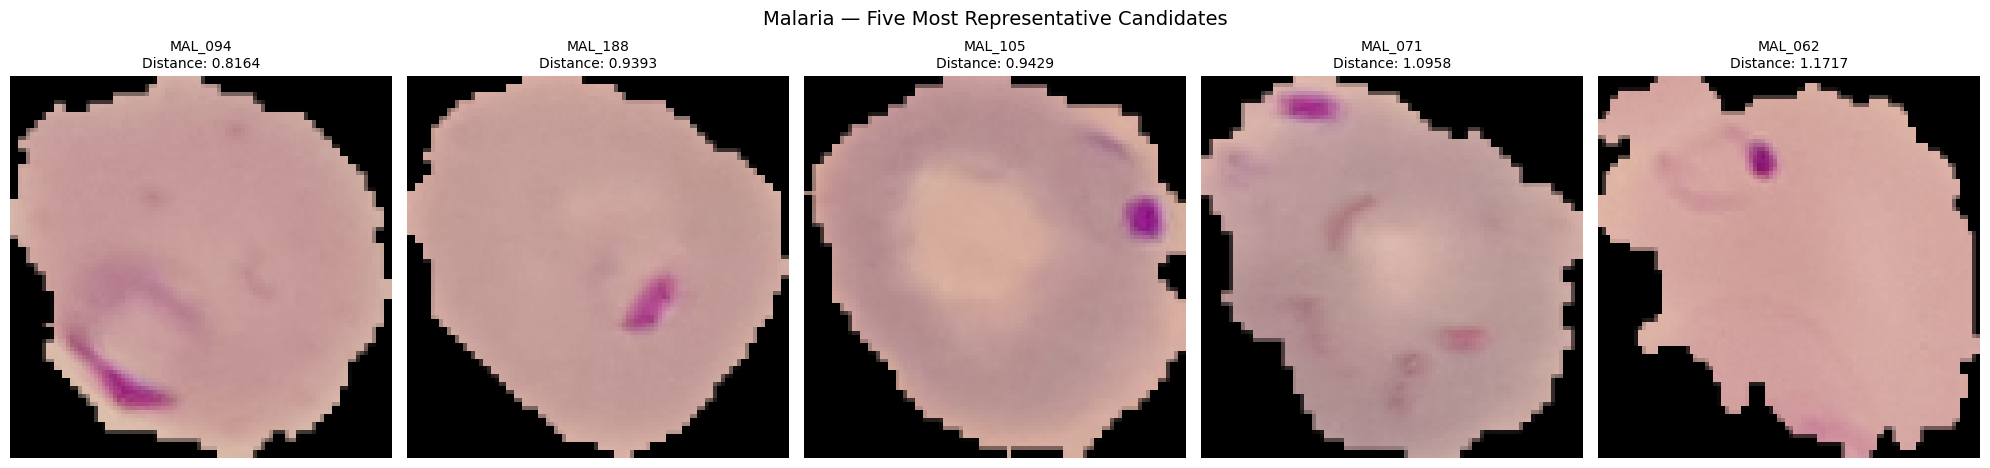

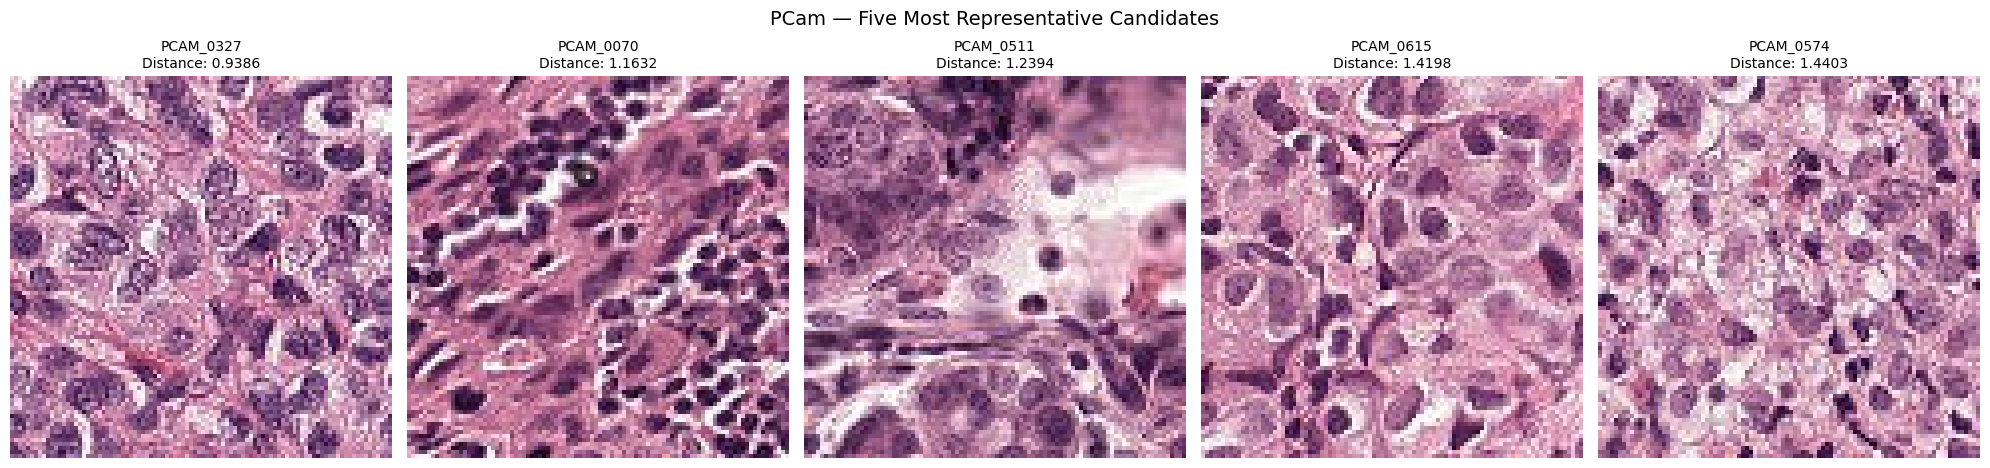

In [47]:
def display_top_candidates(
    ranked_df,
    image_dictionary,
    title,
    n=5
):

    top = ranked_df.head(n)

    fig, axes = plt.subplots(
        1,
        n,
        figsize=(4 * n, 5)
    )

    if n == 1:
        axes = [axes]

    for ax, (_, row) in zip(
        axes,
        top.iterrows()
    ):

        candidate_id = row["candidate_id"]

        image = image_dictionary[candidate_id]

        ax.imshow(image)

        ax.set_title(
            f"{candidate_id}\n"
            f"Distance: {row['euclidean_distance']:.4f}",
            fontsize=10
        )

        ax.axis("off")

    plt.suptitle(
        title,
        fontsize=14
    )

    plt.tight_layout()

    plt.show()


display_top_candidates(
    malaria_ranked,
    malaria_images,
    "Malaria — Five Most Representative Candidates"
)

display_top_candidates(
    pcam_ranked,
    pcam_images,
    "PCam — Five Most Representative Candidates"
)

In [50]:
from pathlib import Path

files = [
    "/content/StainNormalization/src/normalization/stainNorm_Reinhard.py",
    "/content/StainNormalization/src/normalization/stainNorm_Macenko.py"
]

keywords = [
    "mean", "std", "cov", "lab", "od",
    "beta", "mask", "threshold", "normalize"
]

for file in files:
    path = Path(file)
    print(f"\n{'='*25}\n{path.name}\n{'='*25}")

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines):
        if any(word in line.lower() for word in keywords):
            start = max(0, i - 2)
            end = min(len(lines), i + 3)
            print(f"\nLines {start+1}-{end}:")
            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")


stainNorm_Reinhard.py

Lines 1-4:
1: """
2: Normalize a patch stain to the target image using the method of:
3: 
4: E. Reinhard, M. Adhikhmin, B. Gooch, and P. Shirley, ‘Color transfer between images’, IEEE Computer Graphics and Applications, vol. 21, no. 5, pp. 34–41, Sep. 2001.

Lines 13-17:
13: 
14: 
15: def lab_split(I):
16:     """
17:     Convert from RGB uint8 to LAB and split into channels

Lines 15-19:
15: def lab_split(I):
16:     """
17:     Convert from RGB uint8 to LAB and split into channels
18:     :param I: uint8
19:     :return:

Lines 19-23:
19:     :return:
20:     """
21:     I = cv.cvtColor(I, cv.COLOR_RGB2LAB)
22:     I = I.astype(np.float32)
23:     I1, I2, I3 = cv.split(I)

Lines 30-34:
30: def merge_back(I1, I2, I3):
31:     """
32:     Take seperate LAB channels and merge back to give RGB uint8
33:     :param I1:
34:     :param I2:

Lines 40-44:
40:     I3 += 128.0
41:     I = np.clip(cv.merge((I1, I2, I3)), 0, 255).astype(np.uint8)
42:     return cv.cvtColor

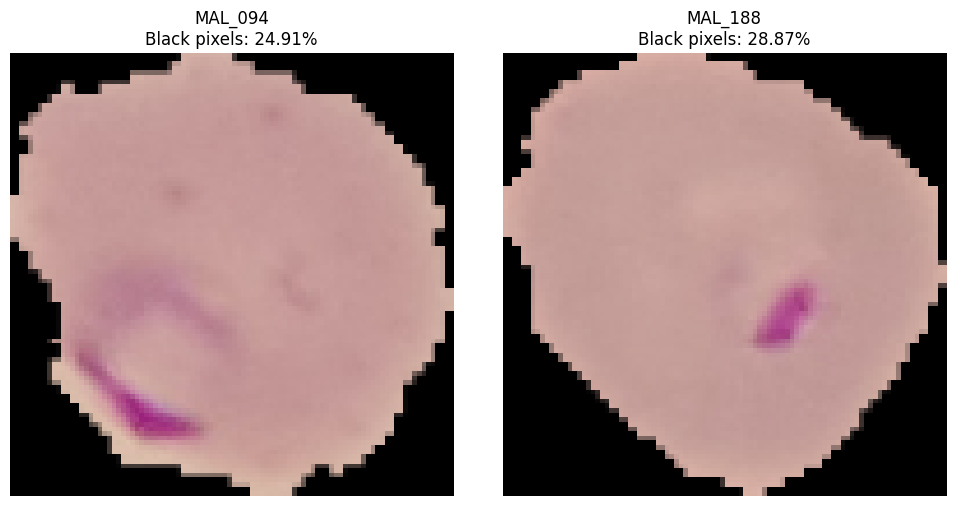

In [51]:
import matplotlib.pyplot as plt
import numpy as np

candidates = ["MAL_094", "MAL_188"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, candidate in zip(axes, candidates):
    image = malaria_images[candidate]

    ax.imshow(image)
    ax.set_title(
        f"{candidate}\n"
        f"Black pixels: {np.mean(np.all(image <= 10, axis=2))*100:.2f}%"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [52]:
from PIL import Image
from pathlib import Path
import numpy as np

candidates = ["MAL_094", "MAL_188"]

for candidate_id in candidates:
    index = int(candidate_id.split("_")[1])
    image_path = Path(malaria_candidate_paths[index])

    image = np.asarray(Image.open(image_path).convert("RGB"))

    pure_black = np.all(image <= 2, axis=2)
    near_black = np.all(image <= 10, axis=2)

    print(f"\n{candidate_id}")
    print("Original image:", image.shape)
    print("Path:", image_path)
    print(f"Pure black pixels (<=2): {pure_black.mean()*100:.2f}%")
    print(f"Near-black pixels (<=10): {near_black.mean()*100:.2f}%")


MAL_094
Original image: (130, 133, 3)
Path: /content/malaria/cell_images/Parasitized/C82P43ThinF_IMG_20150817_123824_cell_192.png
Pure black pixels (<=2): 26.18%
Near-black pixels (<=10): 26.18%

MAL_188
Original image: (139, 139, 3)
Path: /content/malaria/cell_images/Parasitized/C39P4thinF_original_IMG_20150622_111206_cell_76.png
Pure black pixels (<=2): 29.89%
Near-black pixels (<=10): 29.89%


cell 17(chosen images are MAL_094 and PCAM_0327)

In [53]:
# ============================================================
# MANUAL REFERENCE SELECTION
# ============================================================

SELECTED_MALARIA_CANDIDATE_ID = "MAL_094"

SELECTED_PCAM_CANDIDATE_ID = "PCAM_0327"


def validate_selection(
    selected_id,
    ranked_df,
    image_dictionary,
    dataset_name
):

    if selected_id is None:

        raise ValueError(
            f"Select a candidate for {dataset_name} first."
        )

    matching = ranked_df[
        ranked_df["candidate_id"] == selected_id
    ]

    if len(matching) != 1:

        raise ValueError(
            f"Invalid candidate ID: {selected_id}"
        )

    if selected_id not in image_dictionary:

        raise ValueError(
            "Selected candidate image is unavailable."
        )

    return matching.iloc[0]


# Do not proceed until both IDs are entered.

malaria_selection = validate_selection(
    SELECTED_MALARIA_CANDIDATE_ID,
    malaria_ranked,
    malaria_images,
    "Malaria"
)

pcam_selection = validate_selection(
    SELECTED_PCAM_CANDIDATE_ID,
    pcam_ranked,
    pcam_images,
    "PCam"
)

print("Both reference selections validated.")

Both reference selections validated.


In [54]:
malaria_reference = malaria_images[
    SELECTED_MALARIA_CANDIDATE_ID
]

pcam_reference = pcam_images[
    SELECTED_PCAM_CANDIDATE_ID
]

MALARIA_REFERENCE_PATH = (
    OUTPUT_DIR / "reference_malaria.png"
)

PCAM_REFERENCE_PATH = (
    OUTPUT_DIR / "reference_pcam.png"
)

# Save as RGB PNG.

Image.fromarray(
    malaria_reference
).save(
    MALARIA_REFERENCE_PATH,
    format="PNG"
)

Image.fromarray(
    pcam_reference
).save(
    PCAM_REFERENCE_PATH,
    format="PNG"
)

print("Reference images saved.")

print(MALARIA_REFERENCE_PATH)
print(PCAM_REFERENCE_PATH)

Reference images saved.
/content/StainNormalization/data/reference_malaria.png
/content/StainNormalization/data/reference_pcam.png


In [55]:
for path in [
    MALARIA_REFERENCE_PATH,
    PCAM_REFERENCE_PATH
]:

    assert path.exists()

    image = Image.open(path).convert("RGB")

    array = np.asarray(image)

    assert array.shape == (96, 96, 3)

    assert array.dtype == np.uint8

    assert np.isfinite(array).all()

    print("\n", path.name)

    print("Dimensions:", image.size)

    print("Mode:", image.mode)

    print("Data type:", array.dtype)

    print("Minimum:", array.min())

    print("Maximum:", array.max())

    print("File size:", path.stat().st_size, "bytes")

print("\nBoth reference images passed verification.")


 reference_malaria.png
Dimensions: (96, 96)
Mode: RGB
Data type: uint8
Minimum: 0
Maximum: 224
File size: 8798 bytes

 reference_pcam.png
Dimensions: (96, 96)
Mode: RGB
Data type: uint8
Minimum: 0
Maximum: 255
File size: 26333 bytes

Both reference images passed verification.


In [56]:
def build_selection_metadata(
    dataset_name,
    selected_id,
    selected_row,
    statistics,
    candidate_count,
    ranked_df
):

    metadata = {

        "dataset": dataset_name,

        "selection_seed": SEED,

        "candidate_count_sampled": candidate_count,

        "candidate_count_eligible": int(
            len(ranked_df)
        ),

        "number_of_features": len(FEATURE_NAMES),

        "feature_names": FEATURE_NAMES,

        "standardization": "Z-score",

        "representative_profile": "Feature-wise median",

        "distance_metric": "Euclidean distance",

        "selected_candidate_id": selected_id,

        "selected_euclidean_distance": float(
            selected_row["euclidean_distance"]
        ),

        "quality_metrics": {

            "gray_std": float(
                selected_row["gray_std"]
            ),

            "white_fraction": float(
                selected_row["white_fraction"]
            ),

            "laplacian_variance": float(
                selected_row["laplacian_variance"]
            )

        },

        "feature_statistics": statistics,

        "reference_image_size": [
            96,
            96
        ],

        "resize_interpolation": "INTER_LINEAR"

    }

    # Add dataset-specific source information.

    if dataset_name == "NIH Malaria":

        metadata["source_path"] = str(
            selected_row["source_path"]
        )

    elif dataset_name == "PCam":

        metadata["original_split"] = str(
            selected_row["original_split"]
        )

        metadata["original_index"] = int(
            selected_row["original_index"]
        )

    return metadata


malaria_metadata = build_selection_metadata(
    "NIH Malaria",
    SELECTED_MALARIA_CANDIDATE_ID,
    malaria_selection,
    malaria_statistics,
    MALARIA_CANDIDATES,
    malaria_ranked
)

pcam_metadata = build_selection_metadata(
    "PCam",
    SELECTED_PCAM_CANDIDATE_ID,
    pcam_selection,
    pcam_statistics,
    PCAM_CANDIDATES,
    pcam_ranked
)

with open(
    OUTPUT_DIR / "reference_malaria_metadata.json",
    "w"
) as f:

    json.dump(
        malaria_metadata,
        f,
        indent=4
    )


with open(
    OUTPUT_DIR / "reference_pcam_metadata.json",
    "w"
) as f:

    json.dump(
        pcam_metadata,
        f,
        indent=4
    )


# Save complete candidate evaluation tables.

malaria_features_df.to_csv(
    OUTPUT_DIR / "malaria_reference_candidates.csv",
    index=False
)

pcam_features_df.to_csv(
    OUTPUT_DIR / "pcam_reference_candidates.csv",
    index=False
)

malaria_ranked.to_csv(
    OUTPUT_DIR / "malaria_reference_ranking.csv",
    index=False
)

pcam_ranked.to_csv(
    OUTPUT_DIR / "pcam_reference_ranking.csv",
    index=False
)

print("Selection metadata and candidate records saved.")

Selection metadata and candidate records saved.


In [57]:
EXPECTED_OUTPUTS = [

    "reference_malaria.png",

    "reference_pcam.png",

    "reference_malaria_metadata.json",

    "reference_pcam_metadata.json",

    "malaria_reference_candidates.csv",

    "pcam_reference_candidates.csv",

    "malaria_reference_ranking.csv",

    "pcam_reference_ranking.csv"

]

print("=" * 65)
print("REFERENCE SELECTION — FINAL OUTPUT AUDIT")
print("=" * 65)

for filename in EXPECTED_OUTPUTS:

    path = OUTPUT_DIR / filename

    assert path.exists(), (
        f"Missing output: {filename}"
    )

    print(
        f"{filename:<45} "
        f"{path.stat().st_size:>10,} bytes"
    )

print("\nAll expected output files exist.")

print("\nSelected references:")

print(
    "Malaria:",
    SELECTED_MALARIA_CANDIDATE_ID
)

print(
    "PCam:",
    SELECTED_PCAM_CANDIDATE_ID
)

print("\nREFERENCE SELECTION COMPLETED.")

REFERENCE SELECTION — FINAL OUTPUT AUDIT
reference_malaria.png                              8,798 bytes
reference_pcam.png                                26,333 bytes
reference_malaria_metadata.json                    3,273 bytes
reference_pcam_metadata.json                       3,244 bytes
malaria_reference_candidates.csv                  87,327 bytes
pcam_reference_candidates.csv                    285,776 bytes
malaria_reference_ranking.csv                     86,496 bytes
pcam_reference_ranking.csv                       284,094 bytes

All expected output files exist.

Selected references:
Malaria: MAL_094
PCam: PCAM_0327

REFERENCE SELECTION COMPLETED.


In [58]:
import os

ROOT = "/content/StainNormalization"

extensions = {".ipynb", ".py", ".csv", ".json", ".png", ".jpg", ".jpeg"}

print("REPOSITORY:", ROOT)
print("=" * 90)

if not os.path.isdir(ROOT):
    print("Repository folder not found!")
else:
    files = []

    for current_dir, dirs, filenames in os.walk(ROOT):
        dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]

        for filename in filenames:
            ext = os.path.splitext(filename)[1].lower()

            if ext in extensions:
                path = os.path.join(current_dir, filename)
                size = os.path.getsize(path)

                files.append((path, size))

    files.sort(key=lambda x: x[0].lower())

    for path, size in files:
        print(f"{size:>12,} bytes | {os.path.relpath(path, ROOT)}")

    print("\n" + "=" * 90)
    print(f"TOTAL FILES FOUND: {len(files)}")

REPOSITORY: /content/StainNormalization
      87,327 bytes | data/malaria_reference_candidates.csv
      86,496 bytes | data/malaria_reference_ranking.csv
     285,776 bytes | data/pcam_reference_candidates.csv
     284,094 bytes | data/pcam_reference_ranking.csv
       8,798 bytes | data/reference_malaria.png
       3,273 bytes | data/reference_malaria_metadata.json
      26,333 bytes | data/reference_pcam.png
       3,244 bytes | data/reference_pcam_metadata.json
           0 bytes | src/__init__.py
           0 bytes | src/normalization/__init__.py
       4,222 bytes | src/normalization/stain_utils.py
       2,637 bytes | src/normalization/stainNorm_Macenko.py
       2,116 bytes | src/normalization/stainNorm_Reinhard.py

TOTAL FILES FOUND: 13


In [61]:
import os
import requests
from google.colab import userdata

# --------------------------------------------------
# 1. GitHub authentication
# --------------------------------------------------
GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

if not GITHUB_TOKEN:
    raise ValueError("GITHUB_TOKEN not found in Colab Secrets.")

OWNER = "Code-maddie"
REPO = "StainNormalization"
BRANCH = "main"

headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json"
}

# --------------------------------------------------
# 2. Fetch current GitHub repository file inventory
# --------------------------------------------------
url = f"https://api.github.com/repos/{OWNER}/{REPO}/git/trees/{BRANCH}?recursive=1"

response = requests.get(url, headers=headers)
response.raise_for_status()

tree = response.json()["tree"]

remote_files = {
    item["path"]: item
    for item in tree
    if item["type"] == "blob"
}

print("=" * 90)
print("CURRENT FILES ON GITHUB")
print("=" * 90)

for path in sorted(remote_files):
    print(path)

# --------------------------------------------------
# 3. Scan local repository
# --------------------------------------------------
ROOT = "/content/StainNormalization"

local_files = {}

for current_dir, dirs, filenames in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]

    for filename in filenames:
        path = os.path.join(current_dir, filename)
        relative_path = os.path.relpath(path, ROOT).replace("\\", "/")
        local_files[relative_path] = os.path.getsize(path)

# --------------------------------------------------
# 4. Locate relevant files outside the repository
# --------------------------------------------------
outside_files = {}

terms = [
    "reference_selection",
    "reference_feature_extractor",
    "pcam_feature_inputs",
    "pcam_reference_features"
]

for current_dir, dirs, filenames in os.walk("/content"):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", "__pycache__", ".cache", "node_modules"}
    ]

    for filename in filenames:
        path = os.path.join(current_dir, filename)

        if path.startswith(ROOT + os.sep):
            continue

        if any(term.lower() in filename.lower() for term in terms):
            outside_files[path] = os.path.getsize(path)

# --------------------------------------------------
# 5. Compare local and remote inventories
# --------------------------------------------------
print("\n" + "=" * 90)
print("LOCAL REPOSITORY FILES")
print("=" * 90)

for path, size in sorted(local_files.items()):
    status = "ALREADY ON GITHUB" if path in remote_files else "NOT ON GITHUB"
    print(f"{status:20} | {size:>10,} bytes | {path}")

print("\n" + "=" * 90)
print("RELEVANT FILES OUTSIDE REPOSITORY")
print("=" * 90)

for path, size in sorted(outside_files.items()):
    print(f"{size:>10,} bytes | {path}")

print("\n" + "=" * 90)
print("SUMMARY")
print("=" * 90)
print("Remote tracked files:", len(remote_files))
print("Local repository files:", len(local_files))
print("Local files not on GitHub:",
      sum(1 for p in local_files if p not in remote_files))
print("Relevant files outside repository:", len(outside_files))

CURRENT FILES ON GITHUB
.gitignore
Normalization_testing.ipynb
README.md
data/.gitkeep
data/manifests/malaria_test.csv
data/manifests/malaria_train.csv
data/manifests/malaria_val.csv
data/manifests/pcam_all.csv
data/manifests/pcam_test.csv
data/manifests/pcam_train.csv
data/manifests/pcam_val.csv
milestone3_splitting.ipynb
src/__init__.py
src/models/__init__.py
src/normalization/__init__.py
src/normalization/stainNorm_Macenko.py
src/normalization/stainNorm_Reinhard.py
src/normalization/stain_utils.py
src/utils/__init__.py
tests/outputs/macenko_output.png
tests/outputs/reinhard_output.png
tests/sample_images/source.png
tests/sample_images/target.png
tests/smoke_tests/test_macenko.py
tests/smoke_tests/test_reinhard.py

LOCAL REPOSITORY FILES
NOT ON GITHUB        |     87,327 bytes | data/malaria_reference_candidates.csv
NOT ON GITHUB        |     86,496 bytes | data/malaria_reference_ranking.csv
NOT ON GITHUB        |    285,776 bytes | data/pcam_reference_candidates.csv
NOT ON GITHUB   

In [ ]:

from google.colab import userdata, _message
from pathlib import Path
import requests
import base64
import json
import shutil

# ==========================================
# 1. CONFIGURATION
# ==========================================

TOKEN = userdata.get("GITHUB_TOKEN")
REPO = "Code-maddie/StainNormalization"

if not TOKEN:
    raise ValueError("GITHUB_TOKEN not found in Colab Secrets.")

headers = {
    "Authorization": f"Bearer {TOKEN}",
    "Accept": "application/vnd.github+json"
}

api = "https://api.github.com"

ROOT = Path("/content/StainNormalization")
DATA_DIR = ROOT / "data"
REF_DIR = DATA_DIR / "reference_selection"

# ==========================================
# 2. GET CURRENT COLAB NOTEBOOK
# ==========================================

print("Fetching currently open Colab notebook...")

notebook_response = _message.blocking_request("get_ipynb")

if isinstance(notebook_response, dict) and "ipynb" in notebook_response:
    notebook = notebook_response["ipynb"]
else:
    notebook = notebook_response

if isinstance(notebook, str):
    notebook = json.loads(notebook)

if not isinstance(notebook, dict) or "cells" not in notebook:
    raise ValueError(
        "Could not retrieve a valid notebook. Nothing uploaded."
    )

notebook_bytes = json.dumps(
    notebook, ensure_ascii=False, indent=1
).encode("utf-8")

print("Notebook fetched successfully.")
print("Notebook cells:", len(notebook["cells"]))

# ==========================================
# 3. PREPARE REFERENCE-SELECTION FOLDER
# ==========================================

REF_DIR.mkdir(parents=True, exist_ok=True)

reference_files = [
    "malaria_reference_candidates.csv",
    "malaria_reference_ranking.csv",
    "pcam_reference_candidates.csv",
    "pcam_reference_ranking.csv",
    "reference_malaria.png",
    "reference_malaria_metadata.json",
    "reference_pcam.png",
    "reference_pcam_metadata.json"
]

files_to_upload = {
    "reference_selection.ipynb": notebook_bytes
}

for filename in reference_files:

    source = DATA_DIR / filename
    destination = REF_DIR / filename

    if not source.exists():
        raise FileNotFoundError(f"Missing file: {source}")

    # Copy into the dedicated reference-selection folder
    shutil.copy2(source, destination)

    files_to_upload[
        f"data/reference_selection/{filename}"
    ] = destination.read_bytes()

# ==========================================
# 4. PREFLIGHT CHECK
# ==========================================

print("\nFiles prepared:")

for name, content in files_to_upload.items():
    print(f"{name} — {len(content):,} bytes")

print("\nTotal files:", len(files_to_upload))

# ==========================================
# 5. GET DEFAULT BRANCH AND LATEST COMMIT
# ==========================================

repo_response = requests.get(
    f"{api}/repos/{REPO}",
    headers=headers
)
repo_response.raise_for_status()

branch = repo_response.json()["default_branch"]
print(f"\nDefault branch: {branch}")

ref_response = requests.get(
    f"{api}/repos/{REPO}/git/ref/heads/{branch}",
    headers=headers
)
ref_response.raise_for_status()

latest_commit_sha = ref_response.json()["object"]["sha"]

commit_response = requests.get(
    f"{api}/repos/{REPO}/git/commits/{latest_commit_sha}",
    headers=headers
)
commit_response.raise_for_status()

base_tree_sha = commit_response.json()["tree"]["sha"]

# ==========================================
# 6. CREATE BLOBS
# ==========================================

tree_entries = []

for filepath, content in files_to_upload.items():

    encoded = base64.b64encode(content).decode("utf-8")

    blob_response = requests.post(
        f"{api}/repos/{REPO}/git/blobs",
        headers=headers,
        json={
            "content": encoded,
            "encoding": "base64"
        }
    )
    blob_response.raise_for_status()

    blob_sha = blob_response.json()["sha"]

    tree_entries.append({
        "path": filepath,
        "mode": "100644",
        "type": "blob",
        "sha": blob_sha
    })

    print("Created blob:", filepath)

# ==========================================
# 7. CREATE TREE
# ==========================================

tree_response = requests.post(
    f"{api}/repos/{REPO}/git/trees",
    headers=headers,
    json={
        "base_tree": base_tree_sha,
        "tree": tree_entries
    }
)
tree_response.raise_for_status()

new_tree_sha = tree_response.json()["sha"]

# ==========================================
# 8. CREATE COMMIT
# ==========================================

new_commit_response = requests.post(
    f"{api}/repos/{REPO}/git/commits",
    headers=headers,
    json={
        "message": "Add reference selection workflow and artifacts",
        "tree": new_tree_sha,
        "parents": [latest_commit_sha]
    }
)
new_commit_response.raise_for_status()

new_commit_sha = new_commit_response.json()["sha"]

# ==========================================
# 9. UPDATE GITHUB BRANCH
# ==========================================

update_response = requests.patch(
    f"{api}/repos/{REPO}/git/refs/heads/{branch}",
    headers=headers,
    json={
        "sha": new_commit_sha,
        "force": False
    }
)
update_response.raise_for_status()

# ==========================================
# 10. VERIFY UPLOADED FILES
# ==========================================

print("\nVerifying uploaded files...")

for filepath in files_to_upload:

    check = requests.get(
        f"{api}/repos/{REPO}/contents/{filepath}",
        headers=headers,
        params={"ref": branch}
    )
    check.raise_for_status()

    print("VERIFIED:", filepath)

print("\n" + "=" * 60)
print("SUCCESS! REFERENCE SELECTION PUSHED TO GITHUB.")
print("=" * 60)

print("Repository:", f"https://github.com/{REPO}")
print("Branch:", branch)
print("Commit:", new_commit_sha)
print("Files pushed:", len(files_to_upload))
print("Commit URL:", new_commit_response.json()["html_url"])
